# Partial waves: ray-invisible lenses in wave optics and scattering cancellation

Notebook 01 found lenses that are perfectly invisible to rays; do they stay invisible to waves? And how much of the same suppression of scattering can a plain homogeneous shell achieve, with no singular medium at all? Both questions are answered with one exact tool, a multilayer Mie solver for circular cylinders, which also serves as an independent reference for the project's Lippmann-Schwinger solver.

## What this notebook shows

- A stable multilayer cylinder solver (hundreds of layers, high orders, lossy or negative permittivity), validated against the project's Mie code, its own symmetries and thin-cylinder asymptotics.
- The semiclassical partial-wave phase from the book's deflection function, tested on three lenses; for the invisible cylinder it gives $Q\approx4\sin^2(\pi k_0R)$, zero only at integer $k_0R$ (a two-dimensional statement: for the sphere the zeros move to half-integers).
- Why the exact answer for the singular profiles departs from it: the cap on the central singularity removes a band of low orders, and the edge orders leave a floor.
- Scattering cancellation by one homogeneous shell in TM and TE, its loss with size and frequency, and what an all-dielectric shell can and cannot do.
- A cross-check of the Lippmann-Schwinger solver on a core-shell object.

## Conventions

Time dependence $e^{-i\omega t}$: outgoing cylindrical waves are Hankel functions of the first kind $H_m\equiv H_m^{(1)}$, and loss is a positive imaginary part of $\varepsilon$. Lengths are in free-space wavelengths at the design frequency, $\lambda_0=1$, $k_0=2\pi$, unless a section sweeps frequency; $\mu=1$ everywhere. The polarization with $E$ along $z$ is called TM ($E_z$) here, as in the project's `DESIGN.md`; the book calls it TE. TE below means $H_z$. Scattering coefficients $s_m$ are defined by the exterior field $E=\sum_m i^m[J_m(k_0r)+s_mH_m(k_0r)]e^{im\theta}$ for an incident plane wave along $+x$. The book is geometrical optics at this point (sections 8 and 9); the wave statements are ours.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

# Figure style shared by every notebook in notebooks/cloaking (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib
_src = pathlib.Path.cwd().resolve().parents[1] / "src"   # use the bayes_scatter that ships with this checkout
if (_src / "bayes_scatter").is_dir() and str(_src) not in sys.path:
    sys.path.insert(0, str(_src))
from scipy.special import hankel1, hankel1e, jve, jv, jvp, h1vp, spherical_jn, spherical_yn
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq, minimize_scalar
from bayes_scatter import geometry, forward, phantoms
from bayes_scatter import mie as bs_mie
K0 = 2 * np.pi

## 1. The solver

In layer $j$ (outer radius $r_j$, $k_j=k_0\sqrt{\varepsilon_j}$) the order-$m$ field is $u=A\,J_m(k_jr)+B\,H_m(k_jr)$. Both polarizations have the interface conditions "$u$ and $q\,\partial_ru$ continuous", with $q=1$ for TM and $q=1/\varepsilon_j$ for TE ($u=H_z$). The logarithmic derivative $L=q\,u'/u$ is therefore continuous across every interface, and it is the only quantity that has to be carried outward. Starting from the regular core, $L=q_1k_1J_m'/J_m$ at $r_1$. In a layer with inner argument $x_1=k_jr_{j-1}$ and outer argument $x_2=k_jr_j$, the ratio $w$ of the $H$ term to the $J$ term of the field (not of the amplitudes $B/A$) at the inner radius is

$$w=\frac{q k J_m'/J_m-L}{L-q k H_m'/H_m}\Big|_{x_1},\qquad w_{\rm out}=w\,\frac{(H_m/J_m)(x_2)}{(H_m/J_m)(x_1)},\qquad L_{\rm out}=q k\,\frac{J_m'/J_m+w_{\rm out}H_m'/H_m}{1+w_{\rm out}}\Big|_{x_2}.$$

In vacuum ($q=1$, $x_0=k_0r_N$) the same $w_0$ gives $s_m=w_0\,J_m(x_0)/H_m(x_0)$. Only ratios are evaluated: $J_m'/J_m$ from the downward (Miller) recurrence for $J_{m+1}/J_m$, $H_m'/H_m$ from the upward recurrence for $H_{m+1}/H_m$, and $H_m/J_m$ from cumulative logarithms of those ratios. Deep evanescent layers (large $m$, small argument) then give harmless underflow of $w$ to zero instead of overflow. Recurrences run over orders with all layer arguments as one vector.

Cross sections follow from $s_m=s_{-m}$: $\sigma_{\rm sca}=\tfrac4{k_0}\sum_m|s_m|^2$, $\sigma_{\rm ext}=-\tfrac4{k_0}\sum_m{\rm Re}\,s_m$, and $Q=\sigma_{\rm sca}/(2r_N)$.

In [3]:
def log_ratios(x, M):
    """J_m'/J_m, H_m'/H_m and ln(H_m/J_m) for m = 0..M at complex arguments x (Re x >= 0), via recurrences on ratios."""
    x = np.asarray(x, complex)
    start = int(max(M + 2, np.abs(x).max())) + 40            # start of the downward (Miller) recurrence
    R = np.zeros((M + 2, x.size), complex)                    # R[m] = J_m / J_{m-1}
    r = np.zeros(x.size, complex)
    for k in range(start, 0, -1):
        r = 1.0 / (2.0 * k / x - r)
        if k <= M + 1:
            R[k] = r
    Hr = np.zeros((M + 2, x.size), complex)                   # Hr[m] = H_m / H_{m-1}, upward recurrence
    h0e = hankel1e(0, x)
    Hr[1] = hankel1e(1, x) / h0e
    for k in range(1, M + 1):
        Hr[k + 1] = 2.0 * k / x - 1.0 / Hr[k]
    mm = np.arange(M + 1)[:, None]
    with np.errstate(all="ignore"):
        ln0 = np.log(h0e / jve(0, x)) + 1j * x - np.abs(x.imag)   # ln(H_0/J_0) from the exponentially scaled forms
        lnHJ = ln0 + np.concatenate([np.zeros((1, x.size)), np.cumsum(np.log(Hr[1:M + 1]) - np.log(R[1:M + 1]), axis=0)])
    return mm / x - R[1:M + 2], mm / x - Hr[1:M + 2], lnHJ


def multilayer(radii, eps, k0=K0, pol="TM", M=None):
    """Coefficients s_m (m = 0..M) of concentric layers with outer radii `radii`, permittivities `eps`, vacuum outside."""
    r, e = np.asarray(radii, float), np.asarray(eps, complex)
    N = r.size
    M = int(np.ceil(k0 * r[-1])) + 20 if M is None else M
    k = k0 * np.sqrt(e)
    q = np.ones(N, complex) if pol == "TM" else 1.0 / e
    xs = np.concatenate([[k[0] * r[0]], k[1:] * r[:-1], k[1:] * r[1:], [k0 * r[-1]]])   # core, inner and outer layer arguments, vacuum
    Jl, Hl, lnHJ = log_ratios(xs, M)
    L = q[0] * k[0] * Jl[:, 0]
    for j in range(1, N):
        a, b, qk = j, N - 1 + j, q[j] * k[j]
        w1 = (qk * Jl[:, a] - L) / (L - qk * Hl[:, a])
        with np.errstate(all="ignore"):
            w2 = w1 * np.exp(lnHJ[:, b] - lnHJ[:, a])
        L = qk * (Jl[:, b] + w2 * Hl[:, b]) / (1.0 + w2)
    w0 = (k0 * Jl[:, -1] - L) / (L - k0 * Hl[:, -1])
    with np.errstate(all="ignore"):
        return w0 * np.exp(-lnHJ[:, -1])


def sigmas(s, k0=K0):
    """(sigma_sca, sigma_ext) from the coefficients s_m, m >= 0 (negative orders by symmetry)."""
    return (4 / k0 * (abs(s[0]) ** 2 + 2 * np.sum(abs(s[1:]) ** 2)),
            -4 / k0 * (s[0].real + 2 * np.sum(s[1:].real)))


def efficiency(s, radius):
    return sigmas(s)[0] / (2 * radius)

**Thin-cylinder limits (check d).** For a homogeneous cylinder of radius $a$ with $k_0a\ll1$ use $J_m(x)\approx(x/2)^m/m!$ and $H_m(x)\approx-i(m-1)!(2/x)^m/\pi$ for $m\ge1$, $H_0'=-H_1\approx 2i/(\pi x)$. TM, $m=0$: matching $u$ and $u'$ gives
$$s_0=\frac{k_1J_0'(k_1a)J_0(k_0a)-k_0J_0(k_1a)J_0'(k_0a)}{k_0J_0(k_1a)H_0'(k_0a)-k_1J_0'(k_1a)H_0(k_0a)}\;\to\;\frac{-\tfrac a2k_0^2(\varepsilon-1)}{2i/(\pi a)}=\frac{i\pi}{4}(\varepsilon-1)(k_0a)^2,$$
the second denominator term being smaller by a factor $(k_0a)^2\ln(k_0 a)$. The monopole is proportional to $\int(\varepsilon-1)\,dA$, which is the origin of the cancellation condition in section 3. TE, $m=1$: write the exterior field as $x/2-\delta/x$ with $x=k_0r$ and $\delta=2is_1/\pi$, the interior field as $A\,x_1/2$; the conditions $u$ continuous and $r\,\partial_ru_{\rm ext}/u=\varepsilon^{-1}r\,\partial_ru_{\rm int}/u=1/\varepsilon$ at $r=a$ give $\delta=(k_0a)^2(1-\varepsilon)/(2(1+\varepsilon))$, so
$$s_1\to\frac{i\pi}{4}\,\frac{\varepsilon-1}{\varepsilon+1}\,(k_0a)^2 .$$

In [4]:
rng = np.random.default_rng(7)
print("(a) one layer, TM, against bayes_scatter.mie.mie_coefficients (max |difference| over orders)")
errs = []
for a, e in [(0.7, 2.0), (1.3, 5 + 0.5j), (0.05, 12.0), (3.0, 2.0), (2.0, -0.6 + 0j)]:
    s = multilayer([a], [e])
    errs.append(np.abs(s - bs_mie.mie_coefficients(len(s) - 1, a, e, K0)).max())
    print(f"    a = {a:4.2f}, eps = {e!s:>12}: {errs[-1]:.2e}")
check("(a) one layer vs bayes_scatter.mie", max(errs), 1e-10)            # brief; observed is near machine precision

s1 = multilayer([0.7], [2.0], M=30)
check("(b) two layers of equal eps equal one layer", np.abs(multilayer([0.3, 0.7], [2.0, 2.0], M=30) - s1).max(), 1e-12)
check("(b) a vacuum shell changes nothing", np.abs(multilayer([0.7, 0.9], [2.0, 1.0], M=30) - s1).max(), 1e-12)

for pol in ("TM", "TE"):          # eight layers with real eps, including negative values: lossless, so |S_m| = 1
    r = np.cumsum(rng.uniform(0.05, 0.3, 8)); e = rng.uniform(-1.5, 9, 8)
    s = multilayer(r, e, pol=pol)
    check(f"(c) {pol}: |1 + 2 s_m| = 1 (real eps)", np.abs(np.abs(1 + 2 * s) - 1).max(), 1e-10)   # error grows with resonant amplification, observed ~1e-13
    check(f"(c) {pol}: sigma_ext = sigma_sca", np.subtract(*sigmas(s)) / sigmas(s)[0], 1e-10)

a = 1e-2 / K0                  # k0 a = 1e-2
eps0 = 2.0
check("(d) TM s_0 / [i pi/4 (eps - 1)(k0 a)^2] - 1", abs(multilayer([a], [eps0])[0] / (0.25j * np.pi * (eps0 - 1) * (K0 * a) ** 2) - 1), 1e-3)
check("(d) TE s_1 / [i pi/4 (eps - 1)/(eps + 1)(k0 a)^2] - 1", abs(multilayer([a], [eps0], pol="TE")[1] / (0.25j * np.pi * (eps0 - 1) / (eps0 + 1) * (K0 * a) ** 2) - 1), 1e-3)   # corrections are O((k0 a)^2 ln(k0 a)) ~ 1e-4

R10 = 10 / K0                  # (e) Luneburg lens, k0 R = 10, midpoint permittivities, 100/200/400 equal layers
sig = []
for N in (100, 200, 400):
    edges = np.linspace(0, R10, N + 1)
    mid = 0.5 * (edges[1:] + edges[:-1])
    sig.append(sigmas(multilayer(edges[1:], 2 - (mid / R10) ** 2))[0])
print("(e) Luneburg k0 R = 10: sigma_sca for 100, 200, 400 layers:", *[f"{v:.6f}" for v in sig])
check("(e) error ratio (s200 - s100) / (s400 - s200), midpoint rule is second order", (sig[1] - sig[0]) / (sig[2] - sig[1]), 0.1, 4.0)   # ratio 4 for O(h^2); observed deviation about 0.01, tolerance 0.1 covers higher-order terms
check("(e) |sigma(400) - sigma(200)| / sigma(400)", abs(sig[2] - sig[1]) / sig[2], 1e-4)

(a) one layer, TM, against bayes_scatter.mie.mie_coefficients (max |difference| over orders)
    a = 0.70, eps =          2.0: 9.56e-16
    a = 1.30, eps =     (5+0.5j): 7.95e-16
    a = 0.05, eps =         12.0: 3.78e-16
    a = 3.00, eps =          2.0: 8.56e-15
    a = 2.00, eps =    (-0.6+0j): 7.63e-16
PASS  (a) one layer vs bayes_scatter.mie: got 8.56312e-15, target 0, |diff| 8.56e-15 <= 1e-10
PASS  (b) two layers of equal eps equal one layer: got 0, target 0, |diff| 0.00e+00 <= 1e-12
PASS  (b) a vacuum shell changes nothing: got 4.00297e-16, target 0, |diff| 4.00e-16 <= 1e-12
PASS  (c) TM: |1 + 2 s_m| = 1 (real eps): got 2.69784e-13, target 0, |diff| 2.70e-13 <= 1e-10
PASS  (c) TM: sigma_ext = sigma_sca: got 6.50498e-14, target 0, |diff| 6.50e-14 <= 1e-10
PASS  (c) TE: |1 + 2 s_m| = 1 (real eps): got 9.23706e-14, target 0, |diff| 9.24e-14 <= 1e-10
PASS  (c) TE: sigma_ext = sigma_sca: got -4.08473e-14, target 0, |diff| 4.08e-14 <= 1e-10
PASS  (d) TM s_0 / [i pi/4 (eps - 1)(k0 a)^2

## 2. Ray-invisible is not wave-invisible

Take a lens of radius $R$ with $n(r)$ one of three profiles in $x=r/R$: Luneburg $n^2=2-x^2$; Eaton $n^2=2/x-1$; and the invisible profile $x(n^{3/2}+n^{1/2})=2$, solved in closed form by Cardano with $q=\sqrt n$, $q^3+q=2/x$ (book section 9, eqs. (9.4), (9.5); the book's printed cubic in the text before (9.5) misses a square on $r$, which does not affect (9.5) itself). Eaton and invisible diverge at the center, $n\sim x^{-1/2}$ and $n\sim x^{-2/3}$, so the center is capped: $n=n_{\rm cap}$ inside the radius where the profile reaches it. Layers are 400 equal-width shells with the midpoint permittivity (the capped core counts as one).

**Semiclassical prediction.** The book's integrated scattering angle $\Phi(b)=\int_\infty^b\chi\,db$ (8.2) is, in wave language, the phase function: with $l=k_0b$ and $\chi=2\,d\delta/dl$, the partial-wave amplitude $S_m=1+2s_m$ is approximately $e^{2i\delta_m}$, $\delta_m=0$ for $|m|>k_0R$ and
$$2\delta_m=2\Big[\int_{r_t}^{R}\sqrt{k_0^2n^2-\tfrac{m^2}{r^2}}\,dr-\int_{|m|/k_0}^{R}\sqrt{k_0^2-\tfrac{m^2}{r^2}}\,dr\Big],\qquad n(r_t)\,r_t=\tfrac{|m|}{k_0},$$
for $|m|<k_0R$ (difference of radial actions with and without the lens). A uniform deflector, $\chi=-2\pi\nu$ for $b<R$ (9.1), has $\Phi=2\pi\nu(R-b)$, so $2\delta_m=2\pi\nu(k_0R-|m|)$. The invisible profile is $\nu=1$: all orders get $S_m=e^{2\pi ik_0R}$, a uniform phase offset (the optical-path excess found with rays in notebook 01), and for the cylinder
$$Q=\frac{4}{2k_0R}\Big[\tfrac14|S_0-1|^2+\tfrac12\sum_{m\ge1}|S_m-1|^2\Big]\approx 4\sin^2(\pi k_0R),$$
which vanishes only at integer $k_0R$. This is specific to two dimensions. The ray path excess $2\pi R$ is the same for the invisible sphere of notebook 01, but a sphere's radial equation is the cylinder's with $m\to l+\tfrac12$ (Langer shift; the rays cross the axial caustic twice, a Maslov phase of $\pi$), so $S_l\approx-e^{2\pi ik_0R}$, $Q\approx4\cos^2(\pi k_0R)$, and the sphere is nearly invisible at half-integer $k_0R$. Section 2.1 computes both cases for the uncapped profile, for scalar waves. The Eaton lens is $\nu=\tfrac12$: $S_m=e^{i\pi k_0R}(-1)^m$ alternates in sign, the signature of retroreflection. The integrals are done by quadrature for the uncapped profiles, which tests both closed forms.

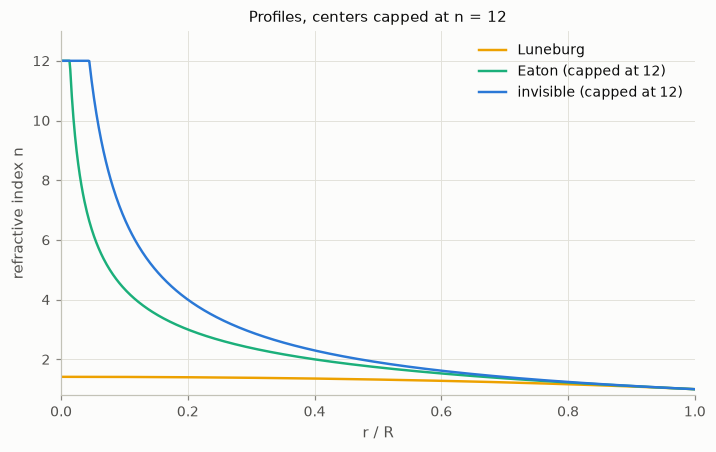

PASS  invisible: max |2 delta_m - 2 pi nu (k0R - m)|, k0R = 15.0: got 2.84217e-14, target 0, |diff| 2.84e-14 <= 1e-06
PASS  invisible: max |2 delta_m - 2 pi nu (k0R - m)|, k0R = 10.5: got 1.42109e-14, target 0, |diff| 1.42e-14 <= 1e-06
PASS  Eaton: max |2 delta_m - 2 pi nu (k0R - m)|, k0R = 15.0: got 7.10543e-15, target 0, |diff| 7.11e-15 <= 1e-06
PASS  Eaton: max |2 delta_m - 2 pi nu (k0R - m)|, k0R = 10.5: got 7.10543e-15, target 0, |diff| 7.11e-15 <= 1e-06


In [5]:
def n_invisible(x):
    a = 1 / x + np.sqrt(1 / x**2 + 1 / 27)          # Cardano; c - sqrt(c^2 + 1/27) = -(1/27)/a avoids cancellation at small x
    return (np.cbrt(a) - np.cbrt(1 / (27 * a))) ** 2

NFUN = {"Luneburg": lambda x: np.sqrt(2 - x**2), "Eaton": lambda x: np.sqrt(2 / x - 1), "invisible": n_invisible}
XCAP = {"Luneburg": lambda nc: 0.0, "Eaton": lambda nc: 2 / (nc**2 + 1), "invisible": lambda nc: 2 / (nc**1.5 + nc**0.5)}


def layers(name, kR, N=400, ncap=12, grade=1.0):
    """Radii and permittivities of N shells for the profile `name` at lens radius R = kR / k0; center capped at n = ncap."""
    R, xc = kR / K0, XCAP[name](ncap)
    if xc == 0:
        edges = np.linspace(0, 1, N + 1)
        return R * edges[1:], NFUN[name](0.5 * (edges[1:] + edges[:-1])) ** 2
    edges = xc + (1 - xc) * np.linspace(0, 1, N) ** grade       # the core x < xc is one layer with eps = ncap^2
    return R * edges, np.concatenate([[ncap**2], NFUN[name](0.5 * (edges[1:] + edges[:-1])) ** 2])


def wkb_2delta(name, kR, m):
    """Semiclassical 2 delta_m of the uncapped profile (see text), by quadrature in x = r / R."""
    mu, n = abs(m) / kR, NFUN[name]
    if mu >= 1:
        return 0.0
    xt = 0.0 if mu == 0 else brentq(lambda x: n(x) * x - mu, 1e-14, 1, xtol=1e-15, rtol=1e-14)
    p = 3 if (mu == 0 and name == "invisible") else 2
    f = lambda u: (lambda x: np.sqrt(max(n(x) ** 2 - mu**2 / x**2, 0.0)) * p * (1 - xt) * u ** (p - 1))(xt + (1 - xt) * u**p)
    return 2 * kR * (quad(f, 0, 1, epsabs=1e-13, epsrel=1e-13, limit=200)[0] - (np.sqrt(1 - mu**2) - mu * np.arccos(mu)))

x = np.linspace(0.002, 1, 800)
fig, ax = plt.subplots()
for name, col, ls in [("Luneburg", CAT[3], "-"), ("Eaton", CAT[2], "-"), ("invisible", CAT[0], "-")]:
    xc = XCAP[name](12)
    xx = np.maximum(x, xc)
    ax.plot(x, NFUN[name](xx), color=col, ls=ls, label=name if name == "Luneburg" else f"{name} (capped at 12)")
ax.set(xlabel="r / R", ylabel="refractive index n", title="Profiles, centers capped at n = 12", ylim=(0.8, 13), xlim=(0, 1))
ax.legend(); plt.show()

for name, nu in [("invisible", 1.0), ("Eaton", 0.5)]:
    for kR in (15.0, 10.5):
        err = max(abs(wkb_2delta(name, kR, m) - 2 * np.pi * nu * (kR - m)) for m in range(int(kR) + 1))
        check(f"{name}: max |2 delta_m - 2 pi nu (k0R - m)|, k0R = {kR}", err, 1e-6)        # brief; quadrature accuracy is ~1e-13

### 2.1 The efficiency of the invisible lens

Exact $Q(k_0R)$ for $k_0R$ from 2 to 30 in steps of 0.05 (the predicted oscillation has period one), three caps, and a homogeneous $\varepsilon=2$ cylinder of the same radius as contrast.

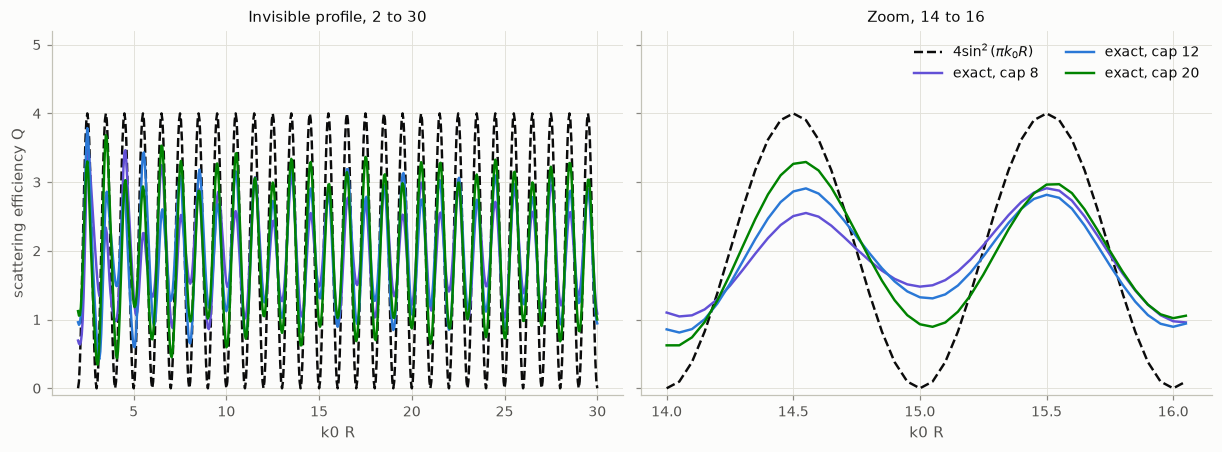

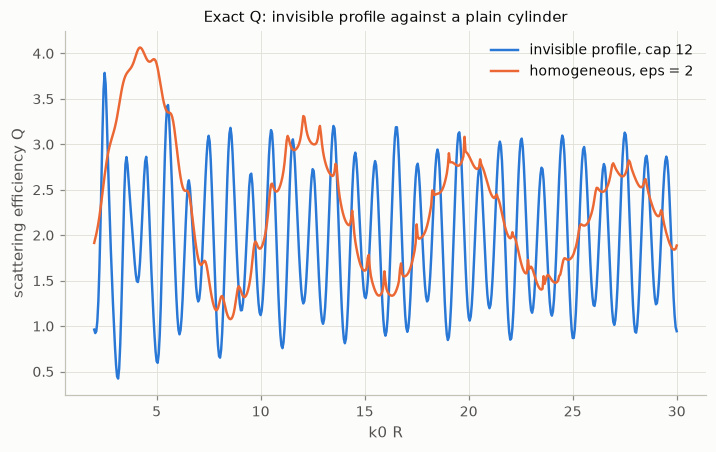

  k0R   4 sin^2   cap 8   cap 12   cap 20   hom eps=2
  5.0     0.000   1.356    0.614    1.237      3.886
 10.0     0.000   1.534    1.121    0.596      1.855
 15.0     0.000   1.479    1.324    0.932      1.610
 20.0     0.000   1.216    1.099    0.871      2.878
  5.5     4.000   2.256    3.411    2.937      3.360
 10.5     4.000   2.579    3.157    3.414      2.558
 15.5     4.000   2.911    2.816    2.964      1.391
 20.5     4.000   2.992    2.741    3.291      2.747
cap  8: Q at integer k0R in [3, 30]: 0.888 to 1.547;  at half-integers: 2.256 to 3.436
cap 12: Q at integer k0R in [3, 30]: 0.614 to 1.569;  at half-integers: 2.556 to 3.786
cap 20: Q at integer k0R in [3, 30]: 0.488 to 1.237;  at half-integers: 2.875 to 3.683
homogeneous eps = 2: Q ranges over 1.076 to 4.065
PASS  layer convergence, cap 12, k0R = 15: Q(400) / Q(1600) - 1: got -0.000132436, target 0, |diff| 1.32e-04 <= 1e-03


In [6]:
KR = np.arange(2, 30 + 1e-9, 0.05)
CAPS = (8, 12, 20)
Qinv = {nc: np.array([efficiency(multilayer(*layers("invisible", k, ncap=nc)), k / K0) for k in KR]) for nc in CAPS}
Qhom = np.array([efficiency(multilayer([k / K0], [2.0]), k / K0) for k in KR])
Qpred = 4 * np.sin(np.pi * KR) ** 2
CAPCOL = {8: CAT[6], 12: CAT[0], 20: CAT[5]}

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, sel, ttl in [(axs[0], slice(None), "Invisible profile, 2 to 30"), (axs[1], (KR > 13.95) & (KR < 16.05), "Zoom, 14 to 16")]:
    ax.plot(KR[sel], Qpred[sel], color=INK, ls="--", label=r"$4\sin^2(\pi k_0R)$")
    for nc in CAPS:
        ax.plot(KR[sel], Qinv[nc][sel], color=CAPCOL[nc], label=f"exact, cap {nc}")
    ax.set(xlabel="k0 R", title=ttl)
axs[0].set_ylabel("scattering efficiency Q"); axs[0].set_ylim(-0.1, 5.2); axs[1].legend(loc="upper right", ncols=2)
plt.show()

fig, ax = plt.subplots()
ax.plot(KR, Qinv[12], color=CAPCOL[12], label="invisible profile, cap 12")
ax.plot(KR, Qhom, color=CAT[1], label="homogeneous, eps = 2")
ax.set(xlabel="k0 R", ylabel="scattering efficiency Q", title="Exact Q: invisible profile against a plain cylinder"); ax.legend()
plt.show()

rows = [5, 10, 15, 20, 5.5, 10.5, 15.5, 20.5]
print("  k0R   4 sin^2   cap 8   cap 12   cap 20   hom eps=2")
for k in rows:
    i = np.argmin(abs(KR - k))
    print(f"{k:5.1f}  {Qpred[i]:8.3f}  {Qinv[8][i]:6.3f}  {Qinv[12][i]:7.3f}  {Qinv[20][i]:7.3f}  {Qhom[i]:9.3f}")
ints = np.isclose(KR, np.round(KR), atol=1e-9) & (KR >= 3)
halves = np.isclose(KR % 1, 0.5, atol=1e-9)
for nc in CAPS:
    print(f"cap {nc:2d}: Q at integer k0R in [3, 30]: {Qinv[nc][ints].min():.3f} to {Qinv[nc][ints].max():.3f};  at half-integers: {Qinv[nc][halves].min():.3f} to {Qinv[nc][halves].max():.3f}")
print(f"homogeneous eps = 2: Q ranges over {Qhom.min():.3f} to {Qhom.max():.3f}")
N_TEST = 1600
Qn = efficiency(multilayer(*layers("invisible", 15.0, N=N_TEST)), 15.0 / K0)
check("layer convergence, cap 12, k0R = 15: Q(400) / Q(1600) - 1", Qinv[12][np.argmin(abs(KR - 15))] / Qn - 1, 1e-3)    # section 1: second-order, differences ~1e-4

The exact efficiency oscillates with period one and is largest near half-integers, as predicted, but with caps of 8 to 20 it does not reach zero at the integers. The layering is excluded by the convergence check. For the cap: the turning parameter $\rho=nr$ of the invisible profile is $2\sqrt n/(n+1)$ in units of $R$, so a cap at index $n_{\rm cap}$ removes every ray with impact parameter below $\rho(n_{\rm cap})R$, i.e. the orders $|m|<k_0\rho R$ see a different profile. Since $\rho\propto x^{1/3}$ near the center, this band closes slowly as the cap grows. The next cell splits $Q$ at $k_0R=15$ by order, then raises the cap far beyond what is physically meaningful, with layers graded toward the center.

cap  k*rho_cap   Q(|m| < k rho_cap)   Q(middle orders)   Q(|m - k0R| <= 3)   Q(|m| > k0R + 3)
  8      9.428               1.4556            0.0001              0.0235           2.41e-08
 12      7.994               1.2963            0.0044              0.0235           2.41e-08
 20      6.389               0.9075            0.0005              0.0235           2.41e-08


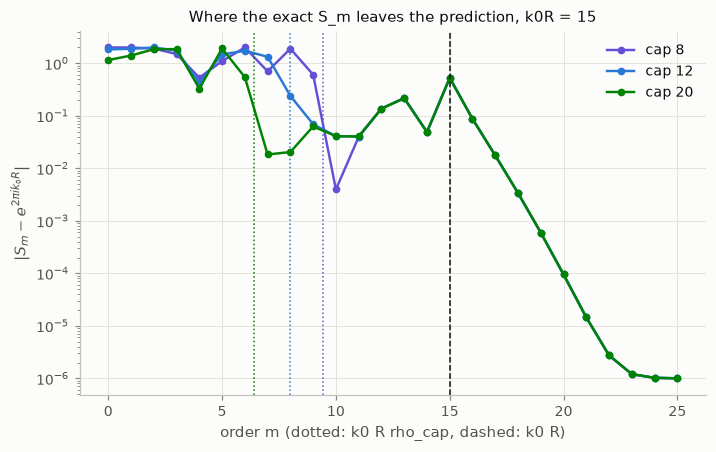


Q at integer k0R against the cap index, graded layers (N = 1000 | 2000):
  n_cap   k rho_cap(k0R=10)   Q(k0R=10)          Q(k0R=15)


     12            5.329     1.1206 |  1.1206     1.3244 |  1.3244
     50            2.773     0.3374 |  0.3374     0.4687 |  0.4687
    200            1.407     0.1127 |  0.1126     0.3972 |  0.3972


   1000            0.632     0.1674 |  0.1673     0.1571 |  0.1571


   5000            0.283     0.0509 |  0.0508     0.0596 |  0.0595
  20000            0.141     0.0354 |  0.0354     0.0281 |  0.0281
PASS  cap -> infinity recovers the prediction: Q(k0R=15, n_cap = 20000) vs 4 sin^2 = 0: got 0.0280744, target 0, |diff| 2.81e-02 <= 5e-02
PASS  graded layers: Q(1000) vs Q(2000) at n_cap = 20000, k0R = 15: got 7.09268e-05, target 0, |diff| 7.09e-05 <= 5e-03


In [7]:
kR = 15.0
mm = np.arange(0, 61)
wgt = np.where(mm == 0, 1.0, 2.0) * 4 / K0 / (2 * kR / K0)        # Q = sum_m wgt_m |s_m|^2
orders = {}
print("cap  k*rho_cap   Q(|m| < k rho_cap)   Q(middle orders)   Q(|m - k0R| <= 3)   Q(|m| > k0R + 3)")
for nc in CAPS:
    S = 1 + 2 * multilayer(*layers("invisible", kR, ncap=nc), M=60)
    orders[nc] = S
    krc = kR * nc * XCAP["invisible"](nc)                          # k0 R rho(cap), rho = n r at the cap
    c = wgt * abs(S - 1) ** 2 / 4
    lo, edge, hi = mm < krc, abs(mm - kR) <= 3, mm > kR + 3
    print(f"{nc:3d}  {krc:9.3f}   {c[lo].sum():18.4f}   {c[~lo & ~edge & ~hi].sum():15.4f}   {c[edge].sum():17.4f}   {c[hi].sum():16.2e}")
fig, ax = plt.subplots()
for nc in CAPS:
    ax.semilogy(mm[:26], abs(orders[nc] - np.exp(2j * np.pi * kR))[:26] + 1e-6, "o-", ms=4, color=CAPCOL[nc], label=f"cap {nc}")
    ax.axvline(kR * nc * XCAP["invisible"](nc), color=CAPCOL[nc], ls=":", lw=1)
ax.axvline(kR, color=INK, ls="--", lw=1)
ax.set(xlabel="order m (dotted: k0 R rho_cap, dashed: k0 R)", ylabel=r"$|S_m-e^{2\pi i k_0R}|$", title="Where the exact S_m leaves the prediction, k0R = 15"); ax.legend()
plt.show()

print("\nQ at integer k0R against the cap index, graded layers (N = 1000 | 2000):")
print("  n_cap   k rho_cap(k0R=10)   Q(k0R=10)          Q(k0R=15)")
cap_limit = {}
for nc in (12, 50, 200, 1000, 5000, 20000):
    q = {k: [efficiency(multilayer(*layers("invisible", k, N=N, ncap=nc, grade=3.0)), k / K0) for N in (1000, 2000)] for k in (10.0, 15.0)}
    cap_limit[nc] = q
    print(f"{nc:7d}   {10 * nc * XCAP['invisible'](nc):14.3f}   {q[10.0][0]:8.4f} | {q[10.0][1]:7.4f}   {q[15.0][0]:8.4f} | {q[15.0][1]:7.4f}")
check("cap -> infinity recovers the prediction: Q(k0R=15, n_cap = 20000) vs 4 sin^2 = 0", cap_limit[20000][15.0][1], 0.05)   # not zero: edge-order floor, see the Q(|m - k0R| <= 3) column
check("graded layers: Q(1000) vs Q(2000) at n_cap = 20000, k0R = 15", abs(cap_limit[20000][15.0][0] - cap_limit[20000][15.0][1]), 5e-3)

So the prediction is a statement about the uncapped profile, and a slowly converging one. Almost all of the scattering of the capped lens comes from the orders below $k_0\rho_{\rm cap}$. The orders just above it follow the semiclassical phase only roughly, but they carry little weight, and the largest remaining contribution is a floor from the edge orders $|m|\approx k_0R$, where the turning point meets the lens boundary and the semiclassical phase is least accurate. The floor does not depend on the cap and is what remains when the cap index grows without bound; the approach to it is slow and not monotonic in the cap.

**The uncapped profile, and the sphere.** No cap is needed if the radial equation is integrated directly. With $u=\sqrt r\,\psi$ for the cylinder and $u=r\,\psi$ for a sphere (scalar waves), both obey
$$u''+\Big[k_0^2n^2-\frac{\nu^2-\tfrac14}{r^2}\Big]u=0,\qquad\nu=m\ \text{(cylinder)},\qquad\nu=l+\tfrac12\ \text{(sphere)},$$
so the sphere is the cylinder at half-integer order. The next cell integrates the solution that is regular at the center outward (from inside the centrifugal barrier for $\nu>\tfrac12$; otherwise from very close to the center, because the local solution varies with $r^{1/3}$) and matches it to Bessel or spherical Bessel functions at $r=R$. For the sphere $Q=\sigma_{\rm sca}/(\pi R^2)=\tfrac{4}{(k_0R)^2}\sum_l(2l+1)|s_l|^2$.

In [8]:
def regular_log_derivative(kR, nu):
    """R u'/u at r = R for the solution of the radial equation that is regular at the center (uncapped invisible profile)."""
    x0 = 1e-15                                            # nu <= 1/2: no barrier
    if nu > 0.5:                                          # start deep inside the centrifugal barrier, where u ~ x^(nu + 1/2)
        x0 = brentq(lambda x: n_invisible(x) * x - 0.01 * nu / kR, 1e-40, 1.0, xtol=1e-45, rtol=1e-12)
    rhs = lambda x, y: [y[1], ((nu**2 - 0.25) / x**2 - (kR * n_invisible(x)) ** 2) * y[0]]
    y = solve_ivp(rhs, (x0, 1.0), [1.0, (nu + 0.5) / x0], method="DOP853", rtol=1e-10, atol=1e-300).y[:, -1]
    return y[1] / y[0]


def uncapped_Q(kR, dim):
    """Exact Q of the uncapped invisible profile, cylinder (dim = 2) or sphere with scalar waves (dim = 3), and max ||S| - 1|."""
    orders = np.arange(int(np.ceil(kR)) + 15)
    s = np.empty(orders.size, complex)
    for q in orders:
        if dim == 2:
            L = regular_log_derivative(kR, float(q)) - 0.5                 # R psi'/psi, from u = sqrt(r) psi
            s[q] = -(kR * jvp(q, kR) - L * jv(q, kR)) / (kR * h1vp(q, kR) - L * hankel1(q, kR))
        else:
            L = regular_log_derivative(kR, q + 0.5) - 1.0                  # R psi'/psi, from u = r psi
            j, dj = spherical_jn(q, kR), spherical_jn(q, kR, derivative=True)
            h, dh = j + 1j * spherical_yn(q, kR), dj + 1j * spherical_yn(q, kR, derivative=True)
            s[q] = -(kR * dj - L * j) / (kR * dh - L * h)
    w = np.where(orders == 0, 1.0, 2.0) * 2 / kR if dim == 2 else (2 * orders + 1) * 4 / kR**2
    return np.sum(w * abs(s) ** 2), np.abs(np.abs(1 + 2 * s) - 1).max()


Qx, unit = {}, 0.0
print("  k0R   cylinder Q   4 sin^2   sphere Q   4 cos^2")
for k in (10.0, 10.5, 15.0, 15.5):
    (q2, u2), (q3, u3) = uncapped_Q(k, 2), uncapped_Q(k, 3)
    Qx[k], unit = (q2, q3), max(unit, u2, u3)
    print(f"{k:5.1f}   {q2:10.4f}   {4 * np.sin(np.pi * k) ** 2:7.3f}   {q3:8.4f}   {4 * np.cos(np.pi * k) ** 2:7.3f}")
check("uncapped profile, all orders: | |S| - 1 |", unit, 1e-8)                                   # lossless; observed ~1e-15
check("uncapped cylinder, k0R = 15: Q against the layered solver at n_cap = 20000", Qx[15.0][0], 0.01, cap_limit[20000][15.0][1])   # two solvers; the cap run is still approaching the limit
check("uncapped cylinder: Q at k0R = 10 (integer)", Qx[10.0][0], 0.05)                            # edge-order floor, not zero
check("uncapped cylinder: Q at k0R = 10.5 against 4", Qx[10.5][0], 0.1, 4.0)
check("scalar sphere: Q at k0R = 10 (integer) against 4", Qx[10.0][1], 0.1, 4.0)
check("scalar sphere: Q at k0R = 10.5 (half-integer)", Qx[10.5][1], 0.1)

  k0R   cylinder Q   4 sin^2   sphere Q   4 cos^2


 10.0       0.0331     0.000     3.9511     4.000


 10.5       3.9730     4.000     0.0595     0.000


 15.0       0.0246     0.000     3.9553     4.000


 15.5       3.9763     4.000     0.0458     0.000
PASS  uncapped profile, all orders: | |S| - 1 |: got 3.77476e-15, target 0, |diff| 3.77e-15 <= 1e-08
PASS  uncapped cylinder, k0R = 15: Q against the layered solver at n_cap = 20000: got 0.024581, target 0.0280744, |diff| 3.49e-03 <= 1e-02
PASS  uncapped cylinder: Q at k0R = 10 (integer): got 0.0330702, target 0, |diff| 3.31e-02 <= 5e-02
PASS  uncapped cylinder: Q at k0R = 10.5 against 4: got 3.97295, target 4, |diff| 2.70e-02 <= 1e-01
PASS  scalar sphere: Q at k0R = 10 (integer) against 4: got 3.95108, target 4, |diff| 4.89e-02 <= 1e-01
PASS  scalar sphere: Q at k0R = 10.5 (half-integer): got 0.0594723, target 0, |diff| 5.95e-02 <= 1e-01


The uncapped cylinder is nearly invisible at integer $k_0R$, where only the edge-order floor remains, and scatters with $Q$ close to 4 at half-integers; it agrees with the layered solver at the largest cap. The scalar sphere does the opposite: close to 4 at integers, nearly invisible at half-integers. The ray path excess $2\pi R$ is the same in both; the wave condition differs by the caustic phase. Vector waves in the sphere were not computed.

### 2.2 Far field of the Eaton lens, and the phases of the Luneburg lens

With $S_m=e^{i\pi k_0R}(-1)^m$ the Eaton pattern $f(\theta)=\sum_ms_me^{im\theta}$, $s_m=\tfrac12(S_m-1)$, has two Dirichlet-kernel peaks of equal weight: the term $-\tfrac12\sum_me^{im\theta}$ peaks forward (the shadow lobe every object has), and $\tfrac12e^{i\pi k_0R}\sum_m(-1)^me^{im\theta}$ peaks backward (the retroreflected beam). Below: the capped exact result (cap 12), the same semiclassical sum, and a homogeneous cylinder, at $k_0R=15$.

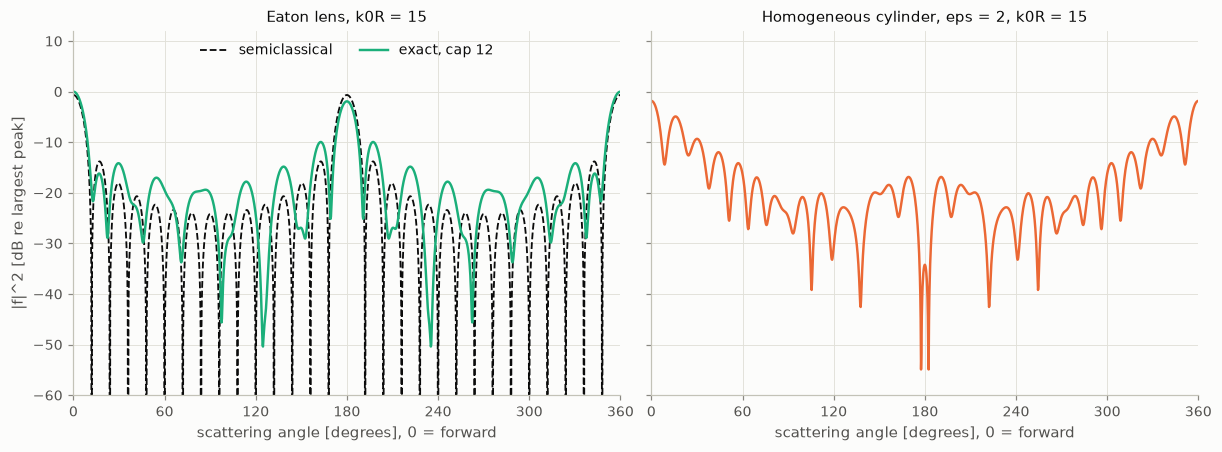

backward lobe / forward [dB], maximum within 0.5 rad of 180 degrees:  Eaton exact  -1.92   Eaton semiclassical   0.00   homogeneous -15.04
exactly 180 degrees over forward [dB] (a null of the homogeneous pattern can sit there):  Eaton exact  -1.92   homogeneous -32.40
PASS  Eaton backward lobe within 3 dB of the forward lobe: got -1.91545, target 0, |diff| 1.92e+00 <= 3e+00
PASS  homogeneous cylinder: backward lobe at least 10 dB below forward: got 0, target 0, |diff| 0.00e+00 <= 0e+00


In [9]:
th = np.linspace(0, 2 * np.pi, 1441)
mm60 = np.arange(61)
def pattern(s):
    return np.abs(s[0] + 2 * np.sum(s[1:, None] * np.cos(mm60[1:, None] * th[None, :]), axis=0)) ** 2
S_eat = multilayer(*layers("Eaton", 15.0, ncap=12), M=60)
S_hom = multilayer([15.0 / K0], [2.0], M=60)
s_wkb = np.array([(np.exp(1j * np.pi * (15.0 - m)) - 1) / 2 if m < 15 else 0.0 for m in mm60])
I = {"exact, cap 12": pattern(S_eat), "semiclassical": pattern(s_wkb), "hom": pattern(S_hom)}
ref = max(v.max() for v in I.values())
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axs[0].plot(np.degrees(th), 10 * np.log10(I["semiclassical"] / ref + 1e-12), color=INK, ls="--", lw=1.2, label="semiclassical")
axs[0].plot(np.degrees(th), 10 * np.log10(I["exact, cap 12"] / ref), color=CAT[2], label="exact, cap 12")
axs[0].set(title="Eaton lens, k0R = 15", ylabel="|f|^2 [dB re largest peak]"); axs[0].legend(loc="upper center", ncol=2)
axs[1].plot(np.degrees(th), 10 * np.log10(I["hom"] / ref), color=CAT[1]); axs[1].set(title="Homogeneous cylinder, eps = 2, k0R = 15")
for ax in axs:
    ax.set(xlabel="scattering angle [degrees], 0 = forward", xlim=(0, 360), ylim=(-60, 12)); ax.set_xticks(range(0, 361, 60))
plt.show()
j0, jb = 0, np.argmin(abs(th - np.pi))
win = abs(th - np.pi) < 0.5
db = lambda v: 10 * np.log10(v[win].max() / v[j0])        # backward lobe (largest value within 0.5 rad of 180 degrees) over forward peak
db_pt = lambda v: 10 * np.log10(v[jb] / v[j0])            # the single direction 180 degrees, for comparison
print(f"backward lobe / forward [dB], maximum within 0.5 rad of 180 degrees:  Eaton exact {db(I['exact, cap 12']):6.2f}   Eaton semiclassical {db(I['semiclassical']):6.2f}   homogeneous {db(I['hom']):6.2f}")
print(f"exactly 180 degrees over forward [dB] (a null of the homogeneous pattern can sit there):  Eaton exact {db_pt(I['exact, cap 12']):6.2f}   homogeneous {db_pt(I['hom']):6.2f}")
check("Eaton backward lobe within 3 dB of the forward lobe", db(I["exact, cap 12"]), 3.0)   # target 0, tolerance 3 dB (observed about 2 dB); no sharper statement is supported by the semiclassical sum, which has equal lobes
check("homogeneous cylinder: backward lobe at least 10 dB below forward", max(0.0, db(I["hom"]) + 10), 0.0)   # lobe maximum in the same window as the Eaton lobe

The Luneburg lens, whose index is finite everywhere, needs no cap, so it isolates the quality of the semiclassical formula itself. Exact phases against the quadrature of the formula above at $k_0R=15$:

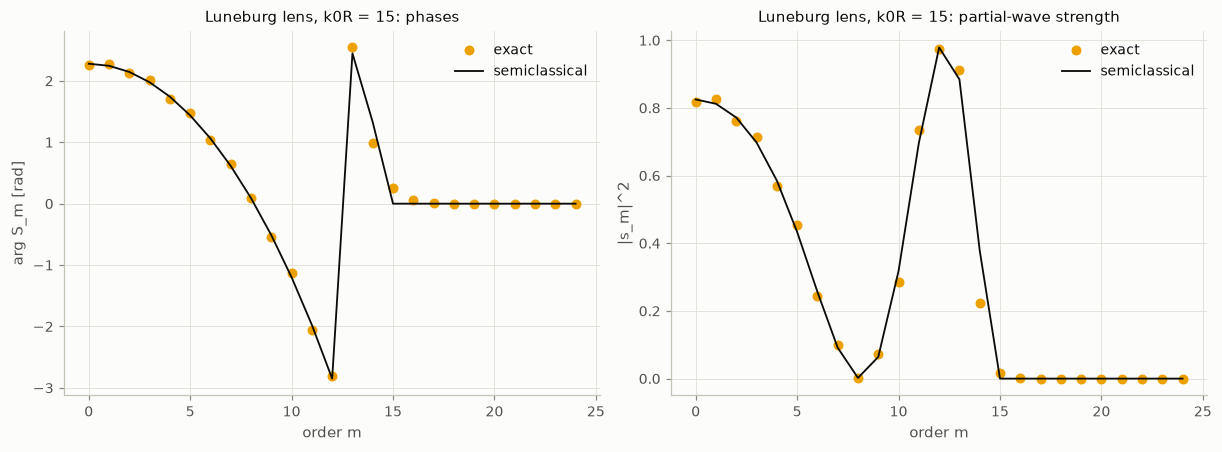

Q exact 1.9468   Q semiclassical 1.9692   relative difference 0.0115
phase error arg(S_exact / S_wkb): rms over |m| <= k0R - 3: 0.0424 rad; max over those orders 0.0881 rad; over the edge orders |m - k0R| <= 2: 0.3402 rad
PASS  Luneburg k0R = 15: semiclassical Q within 3 percent of exact: got 0.0114897, target 0, |diff| 1.15e-02 <= 3e-02


In [10]:
kR = 15.0
s_lun = multilayer(*layers("Luneburg", kR), M=40)
m_arr = np.arange(41)
S_ex = 1 + 2 * s_lun
d2 = np.array([wkb_2delta("Luneburg", kR, m) for m in m_arr])
S_wk = np.exp(1j * d2)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(m_arr[:25], np.angle(S_ex)[:25], "o", color=CAT[3], label="exact")
axs[0].plot(m_arr[:25], np.angle(S_wk)[:25], "-", color=INK, lw=1.2, label="semiclassical")
axs[0].set(xlabel="order m", ylabel="arg S_m [rad]", title="Luneburg lens, k0R = 15: phases"); axs[0].legend()
axs[1].plot(m_arr[:25], abs(S_ex - 1)[:25] ** 2 / 4, "o", color=CAT[3], label="exact")
axs[1].plot(m_arr[:25], abs(S_wk - 1)[:25] ** 2 / 4, "-", color=INK, lw=1.2, label="semiclassical")
axs[1].set(xlabel="order m", ylabel="|s_m|^2", title="Luneburg lens, k0R = 15: partial-wave strength"); axs[1].legend()
plt.show()
q_ex = efficiency(s_lun, kR / K0)
q_wk = wgt[:41] @ (abs(S_wk - 1) ** 2 / 4)
ph = np.angle(S_ex * np.conj(S_wk))
body = m_arr <= kR - 3
print(f"Q exact {q_ex:.4f}   Q semiclassical {q_wk:.4f}   relative difference {abs(q_wk / q_ex - 1):.4f}")
print(f"phase error arg(S_exact / S_wkb): rms over |m| <= k0R - 3: {np.sqrt(np.mean(ph[body] ** 2)):.4f} rad; max over those orders {abs(ph[body]).max():.4f} rad; over the edge orders |m - k0R| <= 2: {abs(ph[abs(m_arr - kR) <= 2]).max():.4f} rad")
check("Luneburg k0R = 15: semiclassical Q within 3 percent of exact", q_wk / q_ex - 1, 0.03)   # observed 1.2 percent; review notes report errors of a few percent over k0R from 6 to 16

For the Luneburg lens the semiclassical formula describes the phases over the body of orders; the error concentrates in the edge orders and gives a small error in $Q$.

## 3. Scattering cancellation

A core ($\varepsilon_c=3$, radius $a_c$) is coated by one shell ($\varepsilon_s$, outer radius $a_s=1.5\,a_c$). All ratios $\sigma/\sigma_{\rm core}$ compare with the bare core of radius $a_c$ at the same frequency. The shell is lossless, so the minimum is a real-part cancellation.

**TM, monopole.** For $k_0a_s\ll1$ the $m=0$ term dominates and is proportional to $\int(\varepsilon-1)\,dA$ (section 1), hence cancels when
$$(\varepsilon_c-1)\,a_c^2+(\varepsilon_s-1)(a_s^2-a_c^2)=0\quad\Longrightarrow\quad\varepsilon_s=1-\frac{(\varepsilon_c-1)\,a_c^2}{a_s^2-a_c^2},$$
which is below one, indeed negative for these parameters: a lossless nonmagnetic shell can cancel the TM monopole only with $\varepsilon_s<1$ (a plasmonic or Drude shell).

**TE, dipole.** The dominant terms are $m=\pm1$. The quasi-static transverse polarizability of a coated cylinder is that of a homogeneous cylinder with the effective permittivity ($f=a_c^2/a_s^2$)
$$\varepsilon_{\rm eff}=\varepsilon_s\,\frac{(\varepsilon_c+\varepsilon_s)+f(\varepsilon_c-\varepsilon_s)}{(\varepsilon_c+\varepsilon_s)-f(\varepsilon_c-\varepsilon_s)},$$
and the thin-cylinder result of section 1 says $s_1\propto(\varepsilon_{\rm eff}-1)/(\varepsilon_{\rm eff}+1)$ vanishes for $\varepsilon_{\rm eff}=1$. Setting $\varepsilon_{\rm eff}=1$ and clearing denominators gives the quadratic
$$(1-f)\,\varepsilon_s^2+(1+f)(\varepsilon_c-1)\,\varepsilon_s-(1-f)\,\varepsilon_c=0,$$
whose roots have a negative product, so exactly one is positive; the printed value is below one but positive.

quasi-static TM shell permittivity: -0.6000;  quasi-static TE shell permittivity (positive root): 0.5241
PASS  TE quadratic gives eps_eff = 1: got 0, target 0, |diff| 0.00e+00 <= 1e-12
k0 a_s = 0.5: minimum of sigma/sigma_core = 0.001695 (-27.7 dB) at eps_s = -0.7848; quasi-static value -0.6000
 k0 a_s   eps_s at minimum   minimum ratio   ratio at quasi-static eps_s
   0.02           -0.6003       4.993e-09   3.506e-08
   0.05           -0.6017       1.940e-07   1.361e-06
   0.10           -0.6070       3.062e-06   2.140e-05
   0.25           -0.6440       1.129e-04   7.707e-04
   0.50           -0.7848       1.695e-03   1.091e-02
PASS  TM minimum approaches the quasi-static eps_s as k0 a_s -> 0 (k0 a_s = 0.02): got -0.600278, target -0.6, |diff| 2.78e-04 <= 1e-03
PASS  TM: shell eps_s = 1 returns the core, ratio = 1: got 1, target 1, |diff| 4.44e-16 <= 1e-12
PASS  TM at k0 a_s = 0.5: minimum below 1 percent of the core: got 0.00169542, target 0, |diff| 1.70e-03 <= 1e-02


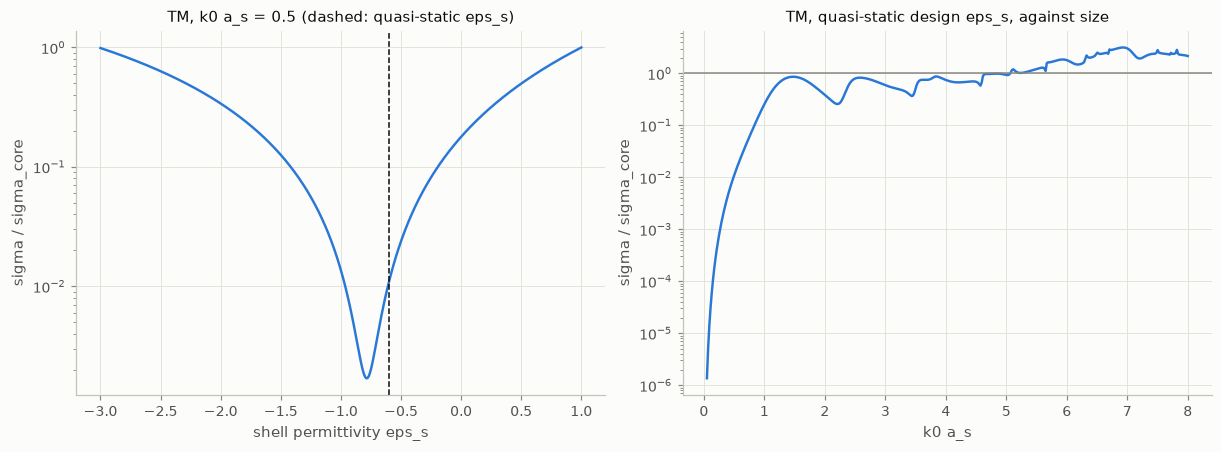

quasi-static design, TM: sigma / sigma_core at k0 a_s = 0.5, 1, 2, 4, 6, 8: 0.011 0.256 0.385 0.747 1.796 2.158
largest ratio over k0 a_s in [0.05, 8]: 3.151 at k0 a_s = 6.92;  first size where ratio exceeds 0.5: 1.17


In [11]:
EC, FAC = 3.0, 1.5
def shell(kas, es, pol="TM", M=None):
    a = kas / K0
    return multilayer([a / FAC, a], [EC, es], pol=pol, M=M)
def ratio(kas, es, pol="TM"):
    """sigma_sca of core + shell over sigma_sca of the bare core (radius a_s / 1.5), same k0."""
    return sigmas(shell(kas, es, pol))[0] / sigmas(multilayer([kas / K0 / FAC], [EC], pol=pol))[0]
es_qs = 1 - (EC - 1) / (FAC**2 - 1)
f = 1 / FAC**2
roots = np.roots([1 - f, (1 + f) * (EC - 1), -EC * (1 - f)])
es_te = roots.real[roots.real > 0][0]
print(f"quasi-static TM shell permittivity: {es_qs:.4f};  quasi-static TE shell permittivity (positive root): {es_te:.4f}")
check("TE quadratic gives eps_eff = 1", abs(es_te * ((EC + es_te) + f * (EC - es_te)) / ((EC + es_te) - f * (EC - es_te)) - 1), 1e-12)

ES = np.linspace(-3, 1, 2000)                                    # avoids eps_s = 0 exactly
r_es = np.array([ratio(0.5, e + 0j) for e in ES])
opt = minimize_scalar(lambda e: ratio(0.5, e + 0j), bounds=(-1.2, -0.4), method="bounded", options={"xatol": 1e-10})
print(f"k0 a_s = 0.5: minimum of sigma/sigma_core = {opt.fun:.4g} ({10 * np.log10(opt.fun):.1f} dB) at eps_s = {opt.x:.4f}; quasi-static value {es_qs:.4f}")
print(" k0 a_s   eps_s at minimum   minimum ratio   ratio at quasi-static eps_s")
mins = {}
for kas in (0.02, 0.05, 0.1, 0.25, 0.5):
    o = minimize_scalar(lambda e: ratio(kas, e + 0j), bounds=(-1.5, -0.3), method="bounded", options={"xatol": 1e-10})
    mins[kas] = o
    print(f"{kas:7.2f}   {o.x:15.4f}   {o.fun:13.3e}   {ratio(kas, es_qs + 0j):.3e}")
check("TM minimum approaches the quasi-static eps_s as k0 a_s -> 0 (k0 a_s = 0.02)", mins[0.02].x, 1e-3, es_qs)   # corrections are O((k0 a)^2 ln k0 a) ~ 1e-3; observed 3e-4
check("TM: shell eps_s = 1 returns the core, ratio = 1", ratio(0.5, 1.0 + 0j), 1e-12, 1.0)
check("TM at k0 a_s = 0.5: minimum below 1 percent of the core", opt.fun, 0.01)                       # cancellation is strong but incomplete at this size

KA = np.linspace(0.05, 8, 400)
r_ka = np.array([ratio(k, es_qs + 0j) for k in KA])
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].semilogy(ES, r_es, color=CAT[0]); axs[0].axvline(es_qs, color=INK, ls="--", lw=1)
axs[0].set(xlabel="shell permittivity eps_s", ylabel="sigma / sigma_core", title="TM, k0 a_s = 0.5 (dashed: quasi-static eps_s)")
axs[1].semilogy(KA, r_ka, color=CAT[0]); axs[1].axhline(1, color=MUTED, lw=1)
axs[1].set(xlabel="k0 a_s", ylabel="sigma / sigma_core", title="TM, quasi-static design eps_s, against size")
plt.show()
print("quasi-static design, TM: sigma / sigma_core at k0 a_s = 0.5, 1, 2, 4, 6, 8:", *[f"{ratio(k, es_qs + 0j):.3f}" for k in (0.5, 1, 2, 4, 6, 8)])
print(f"largest ratio over k0 a_s in [0.05, 8]: {r_ka.max():.3f} at k0 a_s = {KA[r_ka.argmax()]:.2f};  first size where ratio exceeds 0.5: {KA[np.argmax(r_ka > 0.5)]:.2f}")

The tables show the pattern expected from the quasi-static argument. At small size the cancellation is very deep and sits at the quasi-static permittivity; as $k_0a_s$ grows the optimum drifts away from it, becomes shallower, and for the quasi-static design the cancellation is eventually lost altogether, the ratio rising above one (the shell then adds scattering).

For TE the monopole is smaller by two powers of the size, so the dipole $|s_1|$ is the quantity to minimize, normalized by that of the bare core at the same size.

TE, k0 a_s = 0.05: |s_1| minimum 7.615e-09 of the core value, at eps_s = 0.5240 (quasi-static 0.5241)
TE, k0 a_s = 0.5: |s_1| minimum 5.194e-09 of the core value, at eps_s = 0.5114 (quasi-static 0.5241)


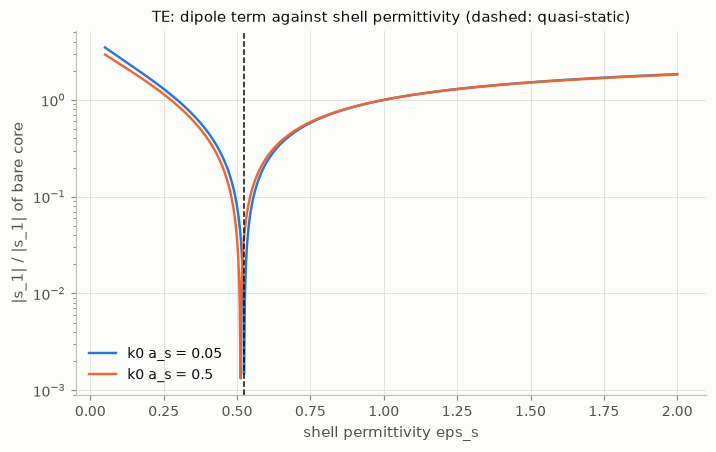

PASS  TE: exact |s_1| minimum at the quasi-static eps_s (k0 a_s = 0.05): got 0.523972, target 0.5241, |diff| 1.28e-04 <= 5e-04


In [12]:
ES_TE = np.linspace(0.05, 2.0, 1500)
fig, ax = plt.subplots()
te_min = {}
for kas, col in [(0.05, CAT[0]), (0.5, CAT[1])]:
    core1 = abs(multilayer([kas / K0 / FAC], [EC], pol="TE", M=6)[1])
    ax.semilogy(ES_TE, [abs(shell(kas, e + 0j, "TE", 6)[1]) / core1 for e in ES_TE], color=col, label=f"k0 a_s = {kas}")
    o = minimize_scalar(lambda e: abs(shell(kas, e + 0j, "TE", 6)[1]), bounds=(0.3, 0.8), method="bounded", options={"xatol": 1e-10})
    te_min[kas] = o
    print(f"TE, k0 a_s = {kas}: |s_1| minimum {o.fun / core1:.3e} of the core value, at eps_s = {o.x:.4f} (quasi-static {es_te:.4f})")
ax.axvline(es_te, color=INK, ls="--", lw=1)
ax.set(xlabel="shell permittivity eps_s", ylabel="|s_1| / |s_1| of bare core", title="TE: dipole term against shell permittivity (dashed: quasi-static)"); ax.legend()
plt.show()
check("TE: exact |s_1| minimum at the quasi-static eps_s (k0 a_s = 0.05)", te_min[0.05].x, 5e-4, es_te)   # corrections O((k0 a)^2) ~ 3e-3 times a small prefactor; observed 1e-4

**All-dielectric shells.** With $\varepsilon_s\ge1$ the shell only adds positive contrast to the monopole, so no quasi-static cancellation exists for TM. Below, $\sigma/\sigma_{\rm core}\ge1$ for $1\le\varepsilon_s\le12$ at $k_0a_s=0.5$; beyond the quasi-static range retardation changes the field inside the shell and the ratio can fall below one. The map shows where, in dB with symmetric limits (clipped beyond them).

k0 a_s = 0.5: sigma/sigma_core for eps_s from 1 to 12 ranges over 1.000000 to 24.906; first value 1.000000000000, value is nondecreasing: True
PASS  all-dielectric shell, k0 a_s = 0.5: sigma/sigma_core >= 1 (violation, if any): got 0, target 0, |diff| 0.00e+00 <= 0e+00


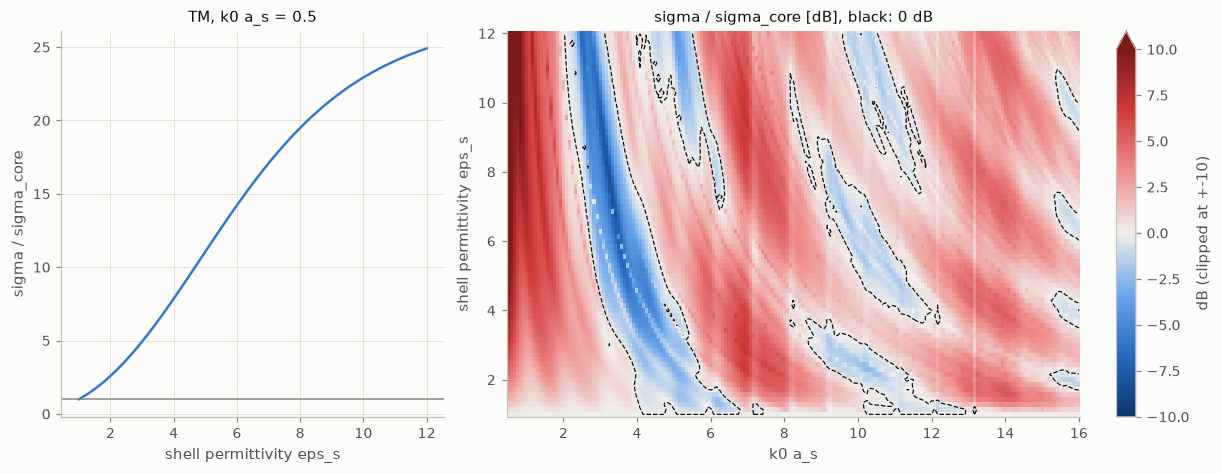

  k0 a_s   best eps_s   best dB   share of eps_s in [1, 12] below 0 dB   below -3 dB   bare-core Q
    0.50         1.00      0.00                                  0.00          0.00          0.234
    1.00         1.00      0.00                                  0.00          0.00          1.319
    2.00         1.00     -0.00                                  0.00          0.00          3.043
    3.00         9.57     -7.37                                  0.68          0.46          4.301
    4.00         4.14     -5.19                                  0.58          0.23          4.317
    5.00        12.00     -3.00                                  0.42          0.01          3.156
    6.00         1.43     -1.14                                  0.13          0.00          1.719
    7.00         1.00     -0.00                                  0.00          0.00          1.029
    8.00         1.00      0.00                                  0.00          0.00          1.433
    9.00  

In [13]:
ES_D = np.linspace(1, 12, 111)
r_d = np.array([ratio(0.5, e + 0j) for e in ES_D])
print(f"k0 a_s = 0.5: sigma/sigma_core for eps_s from 1 to 12 ranges over {r_d.min():.6f} to {r_d.max():.3f}; first value {r_d[0]:.12f}, value is nondecreasing: {bool(np.all(np.diff(r_d) >= -1e-12))}")
check("all-dielectric shell, k0 a_s = 0.5: sigma/sigma_core >= 1 (violation, if any)", min(0.0, r_d.min() - 1 + 1e-12), 0.0)    # equality at eps_s = 1 up to roundoff

KA2, ES2 = np.linspace(0.5, 16, 187), np.linspace(1, 12, 78)
dB = 10 * np.log10(np.array([[ratio(k, e + 0j) for k in KA2] for e in ES2]))
LIM = 10.0
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.5]})
axs[0].plot(ES_D, r_d, color=CAT[0]); axs[0].axhline(1, color=MUTED, lw=1)
axs[0].set(xlabel="shell permittivity eps_s", ylabel="sigma / sigma_core", title="TM, k0 a_s = 0.5")
im = axs[1].pcolormesh(KA2, ES2, np.clip(dB, -LIM, LIM), cmap=DIV, vmin=-LIM, vmax=LIM, shading="nearest")
axs[1].contour(KA2, ES2, dB, levels=[-1e-6], colors=INK, linewidths=0.8)
axs[1].set(xlabel="k0 a_s", ylabel="shell permittivity eps_s", title="sigma / sigma_core [dB], black: 0 dB"); axs[1].grid(False)
fig.colorbar(im, ax=axs[1], label="dB (clipped at +-10)", extend="max"); plt.show()
print("  k0 a_s   best eps_s   best dB   share of eps_s in [1, 12] below 0 dB   below -3 dB   bare-core Q")
for k in (0.5, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16):
    j = np.argmin(abs(KA2 - k)); col = dB[:, j]
    qc = efficiency(multilayer([KA2[j] / K0 / FAC], [EC]), KA2[j] / K0 / FAC)
    print(f"{KA2[j]:8.2f}   {ES2[col.argmin()]:10.2f}   {col.min():7.2f}   {np.mean(col < -1e-6):35.2f}   {np.mean(col < -3):11.2f}   {qc:12.3f}")
print(f"overall: minimum {dB.min():.2f} dB; fraction of the map below 0 dB {np.mean(dB < 0):.2f}")

The map is not a set of isolated spots. For small $k_0a_s$ there is no reduction at all, consistent with the quasi-static argument. Reductions appear along diagonal bands, at combinations of size and shell index, in bands of sizes: a first broad band, a shallower second one, and a third beginning at the top of the range (table above). The bands lie where the bare core's efficiency (last column) is near a maximum of its slow oscillation with size; the match is not one to one, since some sizes with a large core efficiency show no reduction. The shell index that works changes from band to band. That is consistent with interference across the shell or with detuning of the core's own response, rather than with cancellation of a static contrast; which of the two it is was not analyzed. The reductions are shallow compared with the quasi-static deep minima above.

**Bandwidth.** The cancellation is an identity between a static contrast integral and a shell permittivity, so a dispersive shell can satisfy it at one frequency only. Take a Drude shell $\varepsilon_s(\omega)=1-(1-\varepsilon_{s0})(\omega_0/\omega)^2$ designed at $\omega_0$ with the quasi-static value $\varepsilon_{s0}$ for $k_0a_s=0.5$, and a nondispersive core. At $\omega/\omega_0$ the sizes scale as $k_0a_s=0.5\,\omega/\omega_0$.

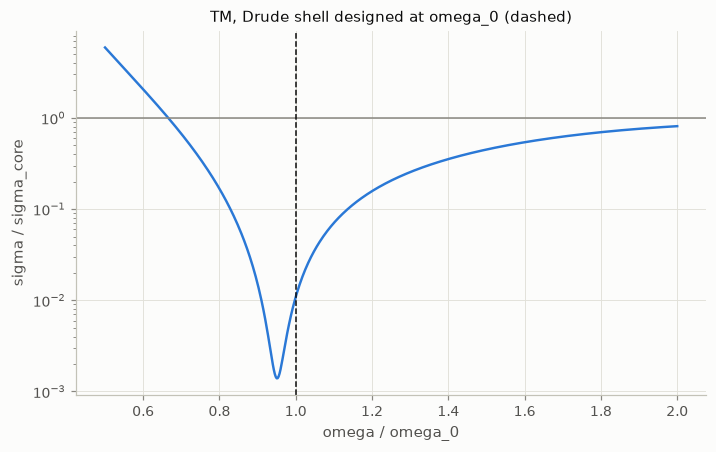

the ratio is above 1 (the shell adds scattering) for omega/omega_0 up to 0.665, and below 1 from there to the end of the range: True
minimum 1.396e-03 at omega/omega_0 = 0.950
band with sigma/sigma_core < 0.1: 0.830 to 1.135 (fractional width 0.321); below 0.5: 0.725 to 1.552
ratio at omega/omega_0 = 0.5, 0.75, 1.0, 1.5, 2.0: 5.921 0.353 0.011 0.450 0.812
largest ratio: 5.92 at omega/omega_0 = 0.500; eps_s there: -5.400
PASS  Drude shell: cancellation near the design frequency (|omega_min / omega_0 - 1|): got 0.05, target 0, |diff| 5.00e-02 <= 1e-01
PASS  Drude shell: minimum below 1 percent of the bare core: got 0.00139554, target 0, |diff| 1.40e-03 <= 1e-02


In [14]:
W = np.linspace(0.5, 2, 601)
r_w = np.array([ratio(0.5 * w, 1 - (1 - es_qs) / w**2 + 0j) for w in W])
fig, ax = plt.subplots()
ax.semilogy(W, r_w, color=CAT[0]); ax.axhline(1, color=MUTED, lw=1); ax.axvline(1, color=INK, ls="--", lw=1)
ax.set(xlabel="omega / omega_0", ylabel="sigma / sigma_core", title="TM, Drude shell designed at omega_0 (dashed)")
plt.show()
iw = r_w.argmin()
cross = W[(W < 1) & (r_w > 1)].max()
print(f"the ratio is above 1 (the shell adds scattering) for omega/omega_0 up to {cross:.3f}, and below 1 from there to the end of the range: {bool(np.all(r_w[W > cross + 1e-9] < 1))}")
print(f"minimum {r_w[iw]:.3e} at omega/omega_0 = {W[iw]:.3f}")
below = W[r_w < 0.1]
print(f"band with sigma/sigma_core < 0.1: {below.min():.3f} to {below.max():.3f} (fractional width {(below.max() - below.min()) / W[iw]:.3f}); below 0.5: {W[r_w < 0.5].min():.3f} to {W[r_w < 0.5].max():.3f}")
print("ratio at omega/omega_0 = 0.5, 0.75, 1.0, 1.5, 2.0:", *[f"{r_w[np.argmin(abs(W - w))]:.3f}" for w in (0.5, 0.75, 1.0, 1.5, 2.0)])
print(f"largest ratio: {r_w.max():.2f} at omega/omega_0 = {W[r_w.argmax()]:.3f}; eps_s there: {1 - (1 - es_qs) / W[r_w.argmax()] ** 2:.3f}")
check("Drude shell: cancellation near the design frequency (|omega_min / omega_0 - 1|)", abs(W[iw] - 1), 0.1)     # finite-size shift of the minimum, section 3 table: of order 10 percent in eps_s at k0 a_s = 0.5
check("Drude shell: minimum below 1 percent of the bare core", r_w[iw], 0.01)

The suppression is a band around $\omega_0$ rather than a line, and its depth is limited by the finite size, which already moves the minimum slightly off $\omega_0$ (section 3, first table). Below $\omega_0$ the shell permittivity becomes more negative and the quasi-static balance fails on the other side; the ratio is above one only below the crossover frequency printed above (about two thirds of $\omega_0$), and between it and $\omega_0$ the shell still reduces the scattering; above $\omega_0$ the ratio rises slowly and stays below one over the plotted range.

## 4. Cross-check of the project's Lippmann-Schwinger solver

The multilayer solver gives exact line-source data for a centered core-shell cylinder. For a transmitter at $(\rho_t,\varphi_t)$ and a receiver at $(\rho_r,\varphi_r)$, both outside the object, the form used in `bayes_scatter/mie.py` generalizes to layers by replacing the one-layer coefficient with $s_m$:
$$u_{\rm sc}=\frac i4\sum_{m=-\infty}^{\infty}s_m\,H_m(k_0\rho_t)\,H_m(k_0\rho_r)\,e^{im(\varphi_r-\varphi_t)}=\frac i4\Big[s_0H_0H_0+2\sum_{m\ge1}s_mH_mH_m\cos m(\varphi_r-\varphi_t)\Big].$$
The normalization is confirmed first against the project's homogeneous-cylinder code. The object is a core of radius 0.3 with $\varepsilon=3$ in a shell out to radius 0.6 with $\varepsilon=1.6$, painted onto the grid with coverage-weighted boundary pixels (`phantoms.coverage`, `phantoms.paint`). The antennas are the book benchmark's 40 transmitters on radius 4 and 60 receivers on radius 4.5, around a domain of side 1.5.

PASS  normalization: homogeneous cylinder, multilayer data vs bayes_scatter.mie_scattered (relative max error): got 6.12271e-16, target 0, |diff| 6.12e-16 <= 1e-10
PASS  data are converged in the number of orders (M = 70 vs 100): got 0, target 0, |diff| 0.00e+00 <= 1e-12
   n   pixel size   relative error ||d_LS - d_exact|| / ||d_exact||   max |error| / max |d_exact|


  48       0.0312                                           0.0168                        0.0124


  64       0.0234                                           0.0122                        0.0091


  96       0.0156                                           0.0056                        0.0041


 128       0.0117                                           0.0050                        0.0036


 192       0.0078                                           0.0028                        0.0020
fitted error ~ h^p over n = 48 to 192: p = 1.30

integral of the contrast over the grid, painted / exact - 1: n=48: -5.68e-03 n=64: -5.04e-03 n=96: -2.31e-03 n=128: -2.23e-03 n=192: -1.29e-03
painted object fixed (n = 64), integral equation refined by replicating each pixel f x f times:
   f   grid   error vs exact core-shell   change from previous refinement (relative to ||d_exact||)
   1     64                      0.0122


   2    128                      0.0104                           0.0020


   4    256                      0.0100                           0.0005
PASS  solver-only discretization error at n = 64 (replicated x4 vs x1, relative to the data): got 0.0024742, target 0, |diff| 2.47e-03 <= 5e-03
PASS  solver refinement is second order: change(x1 to x2) / change(x2 to x4): got 3.98173, target 4, |diff| 1.83e-02 <= 2e+00
PASS  Lippmann-Schwinger error at n = 128 is below one percent: got 0.00498625, target 0, |diff| 4.99e-03 <= 1e-02
PASS  error decreases with n (error(128) / error(48)): got 0.297052, target 0, |diff| 2.97e-01 <= 7e-01
PASS  error at n = 48: got 0.0167857, target 0, |diff| 1.68e-02 <= 3e-02


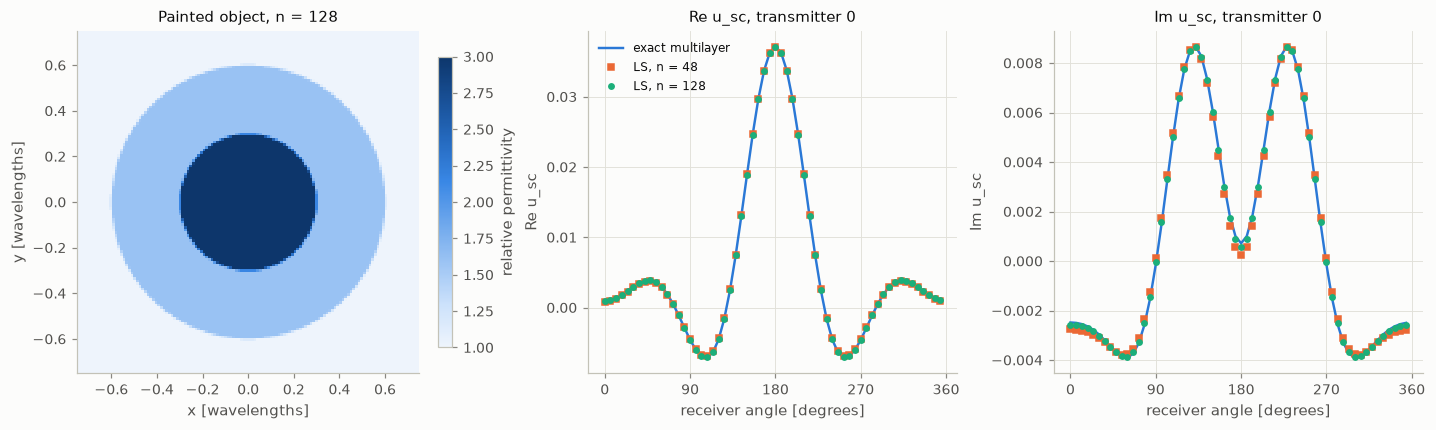

In [15]:
def exact_data(tx, rx, radii, eps, M=70):
    """Exact scattered line-source data (Nt, Nr) of centered concentric layers; M = 70 orders is far past the last significant one."""
    s, m = multilayer(radii, eps, M=M), np.arange(M + 1)
    rt, rr = np.linalg.norm(tx, axis=1), np.linalg.norm(rx, axis=1)
    pt, pr = np.arctan2(tx[:, 1], tx[:, 0]), np.arctan2(rx[:, 1], rx[:, 0])
    cosm = np.cos(m[:, None, None] * (pr[None, None, :] - pt[None, :, None]))
    return 0.25j * np.einsum("m,mt,mr,mtr->tr", np.where(m == 0, 1.0, 2.0) * s, hankel1(m[:, None], K0 * rt[None]), hankel1(m[:, None], K0 * rr[None]), cosm)

setup0 = geometry.ch15_setup(n=64, side=1.5)
tx, rx = setup0.antennas.tx, setup0.antennas.rx
ref = bs_mie.mie_scattered(tx, rx, 0.5, 2.0)
d_hom = exact_data(tx, rx, [0.5], [2.0])
check("normalization: homogeneous cylinder, multilayer data vs bayes_scatter.mie_scattered (relative max error)", abs(d_hom - ref).max() / abs(ref).max(), 1e-10)
check("data are converged in the number of orders (M = 70 vs 100)", np.linalg.norm(exact_data(tx, rx, [0.3, 0.6], [3.0, 1.6], M=100) - exact_data(tx, rx, [0.3, 0.6], [3.0, 1.6])) / np.linalg.norm(exact_data(tx, rx, [0.3, 0.6], [3.0, 1.6])), 1e-12)

d_ex = exact_data(tx, rx, [0.3, 0.6], [3.0, 1.6])
data, errs, chis = {}, {}, {}
print("   n   pixel size   relative error ||d_LS - d_exact|| / ||d_exact||   max |error| / max |d_exact|")
for n in (48, 64, 96, 128, 192):
    setup = geometry.ch15_setup(n=n, side=1.5)
    g = setup.grid
    chi = phantoms.paint(np.zeros((n, n)), phantoms.coverage(g, phantoms._annulus(0, 0, 0.3, 0.6)), 1.6 - 1.0)
    chi = phantoms.paint(chi, phantoms.coverage(g, phantoms._disk(0, 0, 0.3)), 3.0 - 1.0)
    d_ls = np.asarray(forward.Forward(setup, tol=1e-10)(chi)[0])
    chis[n] = chi
    data[n], errs[n] = d_ls, np.linalg.norm(d_ls - d_ex) / np.linalg.norm(d_ex)
    print(f"{n:4d}   {g.h:10.4f}   {errs[n]:46.4f}   {abs(d_ls - d_ex).max() / abs(d_ex).max():27.4f}")
    if n == 128:
        chi128 = chi
nn = np.array([48, 64, 96, 128, 192]); slope = np.polyfit(np.log(1.5 / nn), np.log([errs[n] for n in nn]), 1)[0]
print(f"fitted error ~ h^p over n = 48 to 192: p = {slope:.2f}")

# Split the error: keep the painted object fixed (n = 64) and refine only the integral equation by pixel replication.
A_ex = np.pi * (0.3**2 * 2.0 + (0.6**2 - 0.3**2) * 0.6)
print("\nintegral of the contrast over the grid, painted / exact - 1:", *[f"n={n}: {chis[n].sum() * (1.5 / n) ** 2 / A_ex - 1:.2e}" for n in nn])
d_rep, prev, step = {1: data[64]}, data[64], {}
print("painted object fixed (n = 64), integral equation refined by replicating each pixel f x f times:")
print("   f   grid   error vs exact core-shell   change from previous refinement (relative to ||d_exact||)")
for f in (1, 2, 4):
    if f > 1:
        d_rep[f] = np.asarray(forward.Forward(geometry.ch15_setup(n=64 * f, side=1.5), tol=1e-10)(np.kron(chis[64], np.ones((f, f))))[0])
    ch = np.linalg.norm(d_rep[f] - prev) / np.linalg.norm(d_ex)
    print(f"{f:4d}   {64 * f:4d}   {np.linalg.norm(d_rep[f] - d_ex) / np.linalg.norm(d_ex):25.4f}   {ch:30.4f}" if f > 1 else f"{f:4d}   {64 * f:4d}   {np.linalg.norm(d_rep[f] - d_ex) / np.linalg.norm(d_ex):25.4f}")
    if f > 1:
        step[f] = ch; prev = d_rep[f]
check("solver-only discretization error at n = 64 (replicated x4 vs x1, relative to the data)", np.linalg.norm(d_rep[4] - d_rep[1]) / np.linalg.norm(d_ex), 0.005)
check("solver refinement is second order: change(x1 to x2) / change(x2 to x4)", step[2] / step[4], 1.5, 4.0)
check("Lippmann-Schwinger error at n = 128 is below one percent", errs[128], 0.01)    # observed 0.5 percent
check("error decreases with n (error(128) / error(48))", errs[128] / errs[48], 0.7)           # observed ratio ~0.3; the pixel size drops by 2.7
check("error at n = 48", errs[48], 0.03)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
g = geometry.Grid(128, 1.5)
im = axs[0].imshow((1 + chi128).T, extent=(-0.75, 0.75, -0.75, 0.75), cmap=SEQ)
axs[0].set(xlabel="x [wavelengths]", ylabel="y [wavelengths]", title="Painted object, n = 128"); axs[0].grid(False)
fig.colorbar(im, ax=axs[0], label="relative permittivity", shrink=0.85)
ang = np.degrees(np.arctan2(rx[:, 1], rx[:, 0])) % 360
o = np.argsort(ang)
for ax, fn, lab in [(axs[1], np.real, "Re u_sc"), (axs[2], np.imag, "Im u_sc")]:
    ax.plot(ang[o], fn(d_ex[0])[o], color=CAT[0], label="exact multilayer")
    ax.plot(ang[o], fn(data[48][0])[o], "s", ms=3.5, color=CAT[1], label="LS, n = 48")
    ax.plot(ang[o], fn(data[128][0])[o], ".", ms=7, color=CAT[2], label="LS, n = 128")
    ax.set(xlabel="receiver angle [degrees]", ylabel=lab, title=f"{lab}, transmitter 0"); ax.set_xticks(range(0, 361, 90))
axs[1].legend(loc="upper left", fontsize=8)
plt.show()

The comparison is between the ideal sharp core-shell (exact data) and the painted object that the solver sees, so the table measures two things at once: the discretization of the integral equation and the painting of the object. The replication split separates them. With the painted object held fixed, refining only the integral equation changes the data by a small fraction of the table's error, with successive changes falling at second order, and the error against the exact data barely moves: most of the error is the painted geometry. The coverage-weighted boundary pixels lose a little contrast area (printed integrals), acting like a small uniform phase lag, and this loss improves unevenly with $n$ because it depends on how the circles fall on the pixel lattice. The fitted exponent is therefore the convergence rate of the painting, not of the solver. At the finer of the two resolutions plotted the curves are indistinguishable by eye; at the coarser one small differences are visible near the minima.

## Summary

- **Solver.** The recursion reproduces the project's Mie coefficients to machine precision, is unitary for lossless layers, matches the thin-cylinder asymptotics in both polarizations, and converges at second order in the layer count.
- **Ray-invisible is not wave-invisible.** The invisible lens has the uniform semiclassical phase $S_m=e^{2\pi ik_0R}$ and so $Q\approx4\sin^2(\pi k_0R)$: for the cylinder computed here, invisible to waves only at integer $k_0R$ and strongly scattering at half-integers (notebook 01's uniform path excess seen by waves). The condition is two-dimensional: for the sphere of notebook 01 the Langer shift $m\to l+\tfrac12$ moves it to half-integers (computed in section 2.1 for scalar waves; vector waves were not). With the capped centers of the brief the exact $Q$ has the predicted period but never reaches zero at the integers. The cause is the cap: orders whose turning point lies inside it see a different medium, and since the turning parameter of this profile grows like the cube root of the radius, the cap index must be enormous before the prediction is recovered, down to a floor from the edge orders. The Eaton lens has the predicted alternating phases, giving a backward lobe comparable to the forward one, while a homogeneous cylinder, compared lobe against lobe, backscatters much less. For the Luneburg lens the semiclassical formula gives the phases and $Q$ to a small error.
- **Scattering cancellation.** TM needs a shell permittivity below one (negative here), TE the positive permittivity at which the coated-cylinder effective permittivity is one; the exact minima confirm both. The cancellation is deep only at small $k_0a_s$ and lost as size grows; an all-dielectric shell cannot cancel quasi-statically and reduces scattering only in bands of sizes where the bare core's efficiency is near a maximum of its slow oscillation (consistent with interference or detuning, not analyzed mode by mode); a Drude shell cancels in a band around its design frequency.
- **Cross-check.** The Lippmann-Schwinger solver matches the exact core-shell data at the percent level and improves with resolution, but most of that error is the painting of the sharp object onto pixels, not the integral equation: with the painted object fixed, the solver's own refinement error is small and falls at second order (replication table in section 4).

## Caveats and open ends

- Two dimensions, lossless; a negative-permittivity shell is an idealization, and realistic loss would limit the TM cancellation depth.
- The caps are numerical devices. The infinite-cap limit is approached slowly and not monotonically; the uncapped profile was solved by direct integration at four sizes only, and the sphere for scalar waves only.
- The semiclassical phase uses $m^2$, which in two dimensions is already the Langer-corrected form (in three it would be $(l+\tfrac12)^2$); it is inaccurate for orders near $k_0R$, where the turning point meets the kink of the index profile at the lens edge and the simple connection formula fails. This was measured, not corrected.
- That the dielectric-shell reductions track the maxima of the bare core's efficiency rests on the printed core efficiency and the structure of the map, which stops at the largest size printed; no mode-by-mode analysis was done.
- The solver comparison covers one object and one antenna layout; the split into solver and painting error was made at one painted resolution only (n = 64).
- TE cancellation was checked through the dipole term only, at two sizes; its bandwidth was not examined.

## References

- U. Leonhardt and T. Philbin, *Geometry and Light* (Dover, 2010): section 8, eq. (8.2); section 9, eqs. (9.1) to (9.5) and (9.10).
- A. Alu and N. Engheta, Phys. Rev. E 72, 016623 (2005), "Achieving transparency with plasmonic and metamaterial coatings", the setting of section 3.